# Verificación de sujetos y grabaciones duplicadas

El split (`src/split.py`) supone dos cosas sobre la base Apnea-ECG que PhysioNet no documenta del todo:

1. Hay registros de la **misma persona** (noches distintas): se agrupan por perfil (edad, sexo, altura, peso).
2. Hay registros que son la **misma grabación**: c05 = c06 (documentado), x22 = x35 y x33 = x34 (encontrados acá).

Este notebook muestra la evidencia y lo que no cierra. Tarda alrededor de un minuto, porque calcula el latido promedio de los 70 registros.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import ALL_RECORDS, EXCLUDED, RESULTS_DIR, SAME_RECORDING
from src.data import load_apnea_labels, load_ecg, load_qrs, load_record_info
from src.duplicates import PRE, POST, beat_template, signal_match, template_similarity
from src.split import PROFILE, assign_subjects

FIG = RESULTS_DIR / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
rng = np.random.default_rng(2026)

info = load_record_info()
subj = assign_subjects(info)
PERFIL = info.set_index("record")[PROFILE].astype(str).agg(" ".join, axis=1)
INC = [r for r in ALL_RECORDS if r not in EXCLUDED]      # 67 registros del análisis

# Latido promedio de cada registro y similitud entre todos los pares
T, FS = {}, 100.0
for r in ALL_RECORDS:
    ecg, FS = load_ecg(r)
    T[r] = beat_template(ecg, load_qrs(r), FS)
S = pd.DataFrame(1.0, index=ALL_RECORDS, columns=ALL_RECORDS)
for a, b in combinations(ALL_RECORDS, 2):
    S.loc[a, b] = S.loc[b, a] = template_similarity(T[a], T[b])
print(f"{len(ALL_RECORDS)} registros, {len(INC)} en el análisis, {subj[INC].nunique()} sujetos")

70 registros, 67 en el análisis, 29 sujetos


## 1. ¿Los perfiles repetidos pueden ser casualidad?

Si mezclamos cada columna (edad, sexo, altura, peso) por separado, se conserva la distribución de cada variable pero se rompe la relación entre ellas. Contando cuántos pares de registros quedan con el perfil idéntico en 10.000 mezclas, obtenemos cuántas coincidencias da el azar.

perfiles distintos: 32 | pares con perfil idéntico: 52
por azar: mediana 0, máximo 3 | p = 0.0001


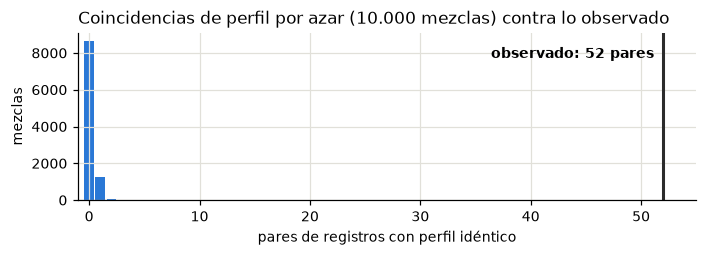

In [2]:
codes = np.column_stack([pd.factorize(info[c])[0] for c in PROFILE]).astype(np.int64)
base = codes.max(axis=0) + 1

def pares_iguales(c):
    key = ((c[:, 0] * base[1] + c[:, 1]) * base[2] + c[:, 2]) * base[3] + c[:, 3]
    _, n = np.unique(key, return_counts=True)
    return int((n * (n - 1) // 2).sum())

obs = pares_iguales(codes)
nulo = np.array([pares_iguales(np.column_stack([rng.permutation(codes[:, j]) for j in range(4)]))
                 for _ in range(10_000)])
p = (1 + (nulo >= obs).sum()) / (1 + len(nulo))
print(f"perfiles distintos: {len(np.unique(codes, axis=0))} | pares con perfil idéntico: {obs}")
print(f"por azar: mediana {np.median(nulo):.0f}, máximo {nulo.max()} | p = {p:.4f}")

fig, ax = plt.subplots(figsize=(6.5, 2.4))
ax.hist(nulo, bins=np.arange(-0.5, nulo.max() + 1.5), color=AZUL, rwidth=0.85)
ax.axvline(obs, color=TINTA, lw=2)
ax.annotate(f"observado: {obs} pares", (obs, ax.get_ylim()[1] * 0.85), xytext=(-6, 0),
            textcoords="offset points", ha="right", fontweight="bold")
ax.set_xlim(-1, obs + 3)
ax.set_xlabel("pares de registros con perfil idéntico")
ax.set_ylabel("mezclas")
ax.set_title("Coincidencias de perfil por azar (10.000 mezclas) contra lo observado", loc="left")
fig.tight_layout(); fig.savefig(FIG / "sujetos_1_permutacion_perfiles.png")

## 2. ¿Qué registros son la misma grabación?

Comparar las señales completas de los 2.415 pares es caro. Primero se descartan los pares cuyo latido promedio no es casi idéntico (r < 0,99) y los que quedan se confirman buscando un tramo de 5 min de uno dentro del otro (`signal_match`). La misma tabla sirve para la sección 4.

In [3]:
filas = []
for a, b in combinations(ALL_RECORDS, 2):
    if S.loc[a, b] >= 0.99:
        lag, r = signal_match(load_ecg(a)[0], load_ecg(b)[0], FS)
        filas.append({"a": a, "b": b, "mismo perfil": PERFIL[a] == PERFIL[b],
                      "r latido": round(S.loc[a, b], 4), "r señal": round(r, 4), "desfase (s)": lag / FS})
cand = pd.DataFrame(filas).sort_values("r señal", ascending=False).reset_index(drop=True)
dup = cand[cand["r señal"] > 0.99]
print(f"pares con latido casi idéntico: {len(cand)} | misma grabación: {len(dup)}")
dup

pares con latido casi idéntico: 19 | misma grabación: 3


,a,b,mismo perfil,r latido,r señal,desfase (s)
0,c05,c06,False,1.0,1.0,80.0
1,x33,x34,False,1.0,1.0,70.0
2,x22,x35,False,1.0,1.0,40.0


In [4]:
tabla = []
for a, b in SAME_RECORDING:
    for r in (a, b):
        i = info.set_index("record").loc[r]
        lab = load_apnea_labels(r)
        tabla.append({"registro": r, "par": f"{a} = {b}", "perfil en la tabla": f"{i.age} {i.sex} {i.height_cm} cm {i.weight_kg} kg",
                      "minutos": len(lab), "minutos de apnea": int(lab.sum()), "excluido": r in EXCLUDED})
pd.DataFrame(tabla).set_index(["par", "registro"])

perfil en la tabla  minutos  minutos de apnea  excluido
par       registro                                                        
c05 = c06 c05       28 F 169 cm 57 kg      466                 3      True
          c06       28 F 171 cm 65 kg      468                 1     False
x22 = x35 x22       27 F 158 cm 53 kg      482                 2      True
          x35       31 M 184 cm 74 kg      483                 0     False
x33 = x34 x33       28 F 169 cm 57 kg      473                 3      True
          x34       30 F 168 cm 56 kg      475                 4     False

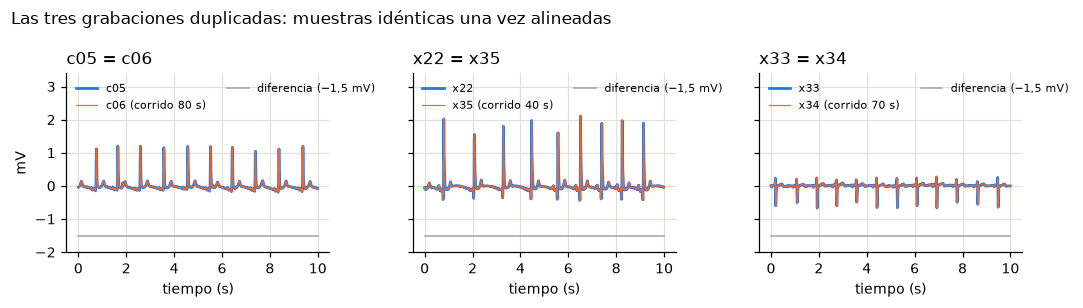

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, (a, b) in zip(axes, SAME_RECORDING):
    xa, xb = load_ecg(a)[0], load_ecg(b)[0]
    lag, _ = signal_match(xa, xb, FS)
    i0, n = int(120 * 60 * FS), int(10 * FS)                  # 10 s desde el minuto 120 de `a`
    t = np.arange(n) / FS
    sa, sb = xa[i0:i0 + n], xb[i0 + lag:i0 + lag + n]
    ax.plot(t, sa, color=AZUL, lw=1.8, label=a)
    ax.plot(t, sb, color=NARANJA, lw=0.8, label=f"{b} (corrido {lag / FS:.0f} s)")
    ax.plot(t, sa - sb - 1.5, color=GRIS, lw=1, label="diferencia (−1,5 mV)")
    ax.set_title(f"{a} = {b}", loc="left")
    ax.set_xlabel("tiempo (s)")
    ax.set_ylim(-2, 3.4)
    ax.legend(loc="upper left", ncol=2, fontsize=7, frameon=False)
axes[0].set_ylabel("mV")
fig.suptitle("Las tres grabaciones duplicadas: muestras idénticas una vez alineadas", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "sujetos_2_duplicados.png")

## 3. ¿El ECG confirma la agrupación?

El latido promedio (mediana de los latidos con RR estable entre las horas 1 y 4, de −250 a +400 ms) funciona como una huella: depende de la anatomía de cada persona y de dónde quedaron los electrodos. Si la agrupación por perfil es correcta, los registros de un mismo sujeto deberían parecerse más entre sí que con los demás. Se usan los 67 registros del análisis, sin los duplicados excluidos (que se parecerían con r = 1 y lo inflarían).

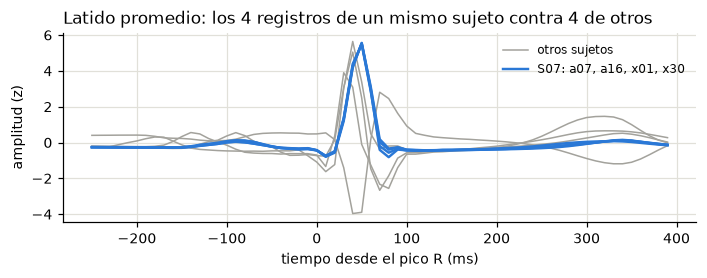

In [6]:
grupo, otros = ["a07", "a16", "x01", "x30"], ["a01", "b05", "c03", "x13"]
t_ms = (np.arange(-PRE, POST)) * 1000 / FS
fig, ax = plt.subplots(figsize=(6.5, 2.6))
for r in otros:
    ax.plot(t_ms, T[r], color=GRIS, lw=1, label="otros sujetos" if r == otros[0] else None)
for r in grupo:
    ax.plot(t_ms, T[r], color=AZUL, lw=1.6, label=f"{subj['a07']}: " + ", ".join(grupo) if r == grupo[0] else None)
ax.set_xlabel("tiempo desde el pico R (ms)"); ax.set_ylabel("amplitud (z)")
ax.set_title("Latido promedio: los 4 registros de un mismo sujeto contra 4 de otros", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "sujetos_3_latidos_ejemplo.png")

r mediano: mismo sujeto 0.942 (54 pares) | distinto 0.737 (2157 pares)
vecino más parecido del mismo sujeto: 40 de 64 registros con grupo | por azar: mediana 1, máximo 12 | p = 0.0001


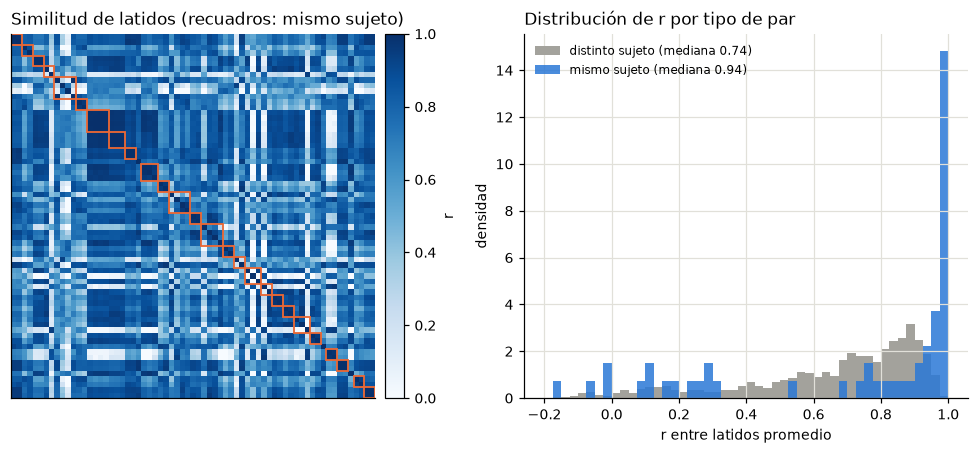

In [7]:
orden = sorted(INC, key=lambda r: (subj[r], r))
M = S.loc[orden, orden].to_numpy()
lab = subj[orden].to_numpy()
iu = np.triu_indices(len(orden), 1)
mismo = lab[iu[0]] == lab[iu[1]]
dentro, entre = M[iu][mismo], M[iu][~mismo]

# Vecino más parecido: ¿es del mismo sujeto? Se compara con mezclar las etiquetas.
Mi = M.copy(); np.fill_diagonal(Mi, -np.inf)
vecino = Mi.argmax(axis=1)
obs_v = int((lab[vecino] == lab).sum())
nulo_v = np.array([(q[vecino] == q).sum() for q in (rng.permutation(lab) for _ in range(10_000))])
p_v = (1 + (nulo_v >= obs_v).sum()) / (1 + len(nulo_v))
con_grupo = int(sum((lab == l).sum() > 1 for l in lab))
print(f"r mediano: mismo sujeto {np.median(dentro):.3f} ({len(dentro)} pares) | distinto {np.median(entre):.3f} ({len(entre)} pares)")
print(f"vecino más parecido del mismo sujeto: {obs_v} de {con_grupo} registros con grupo | "
      f"por azar: mediana {np.median(nulo_v):.0f}, máximo {nulo_v.max()} | p = {p_v:.4f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
im = a1.imshow(np.clip(M, 0, 1), cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
inicio = np.flatnonzero(np.r_[True, lab[1:] != lab[:-1]])
for i0, i1 in zip(inicio, np.r_[inicio[1:], len(lab)]):
    if i1 - i0 > 1:                                    # un recuadro por sujeto con más de un registro
        a1.add_patch(plt.Rectangle((i0 - 0.5, i0 - 0.5), i1 - i0, i1 - i0, fill=False, ec=NARANJA, lw=1.2))
a1.set_xticks([]); a1.set_yticks([]); a1.grid(False)
a1.set_title("Similitud de latidos (recuadros: mismo sujeto)", loc="left")
fig.colorbar(im, ax=a1, fraction=0.046, pad=0.02, label="r")
bins = np.linspace(-0.2, 1, 49)
a2.hist(entre, bins=bins, color=GRIS, density=True, label=f"distinto sujeto (mediana {np.median(entre):.2f})")
a2.hist(dentro, bins=bins, color=AZUL, density=True, alpha=0.85, label=f"mismo sujeto (mediana {np.median(dentro):.2f})")
a2.set_xlabel("r entre latidos promedio"); a2.set_ylabel("densidad")
a2.set_title("Distribución de r por tipo de par", loc="left")
a2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "sujetos_4_similitud.png")

## 4. Mismo latido, distinta noche

En la tabla de la sección 2, los pares con latido casi idéntico que **no** son la misma grabación (r de la señal bajo) tienen todos el mismo perfil. Es la evidencia más directa de que son noches distintas de una misma persona: la morfología coincide, la señal no.

In [8]:
otra_noche = cand[cand["r señal"] < 0.99]
print(f"{len(otra_noche)} pares con latido casi idéntico y señal distinta; "
      f"con el mismo perfil: {int(otra_noche['mismo perfil'].sum())}")
otra_noche

16 pares con latido casi idéntico y señal distinta; con el mismo perfil: 16


,a,b,mismo perfil,r latido,r señal,desfase (s)
3,a16,x01,True,0.9966,0.4402,26115.34
4,a16,x30,True,0.9993,0.4396,23622.19
5,a13,x20,True,0.9964,0.2857,-2354.59
6,x01,x30,True,0.9986,0.1647,14432.02
7,a08,a13,True,0.9982,0.1456,9499.22
8,a08,x20,True,0.9946,0.1351,6477.55
9,x09,x23,True,0.9970,0.1313,26275.73
10,a09,a18,True,0.9965,0.0980,2019.52
11,a15,x27,True,0.9921,0.0827,19687.83
12,a03,x19,True,0.9958,0.0783,-3076.62


## 5. Lo que no cierra

Para cada sujeto con más de un registro, la similitud más baja entre sus registros contra la más alta con registros de otros sujetos. Los puntos debajo de la diagonal son sujetos cuyos registros no se distinguen de los demás por el latido.

La última columna de la tabla compara invirtiendo uno de los dos latidos. En varios casos el latido de un registro es el del otro dado vuelta: lo más probable es que los electrodos se hayan colocado al revés en alguna de las noches. Los paneles de la derecha muestran los dos ejemplos más claros.

,sujeto,registros,peor par,mín. dentro,máx. afuera,r con polaridad invertida
16,S18,"c01, x17, x35",c01-x17,-0.154,0.947,0.762
20,S22,"c06, c07, x34",c06-x34,-0.001,0.958,0.870
4,S05,"a05, a10, a20, x07",a05-a20,0.085,0.934,0.743
17,S19,"c02, c09",c02-c09,0.114,0.968,0.966
3,S04,"a04, a12",a04-a12,0.161,0.957,0.897
15,S17,"b05, x11",b05-x11,0.199,0.966,0.937
13,S15,"b02, b03, x16, x21",b02-x21,0.228,0.969,0.619
11,S13,"a19, x05, x08, x25",a19-x05,0.268,0.946,0.966


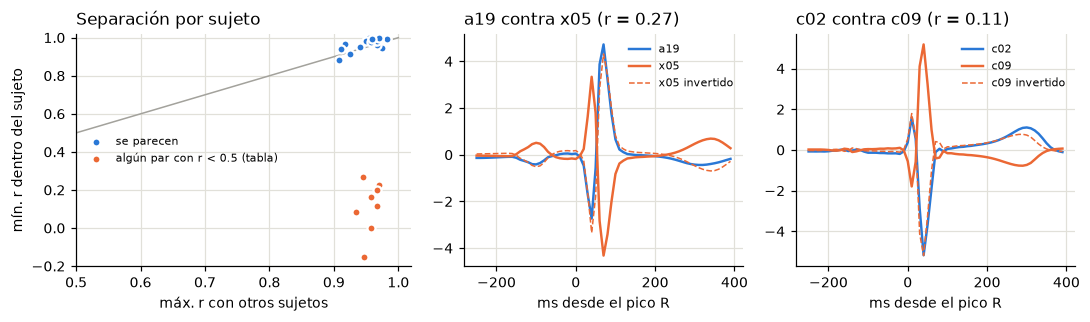

In [9]:
filas = []
for s, recs in pd.Series(INC, index=INC).groupby(subj[INC]):
    recs = list(recs)
    if len(recs) < 2:
        continue
    pares = list(combinations(recs, 2))
    a, b = min(pares, key=lambda ab: S.loc[ab[0], ab[1]])
    fuera = [r for r in INC if subj[r] != s]
    filas.append({"sujeto": s, "registros": ", ".join(recs), "peor par": f"{a}-{b}",
                  "mín. dentro": S.loc[a, b], "máx. afuera": S.loc[recs, fuera].to_numpy().max(),
                  "r con polaridad invertida": template_similarity(T[a], -T[b])})
g = pd.DataFrame(filas)
raros = g[g["mín. dentro"] < 0.5].sort_values("mín. dentro")

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={"width_ratios": [1.2, 1, 1]})
a1.plot([0, 1], [0, 1], color=GRIS, lw=1)
ok = g["mín. dentro"] >= 0.5
a1.scatter(g.loc[ok, "máx. afuera"], g.loc[ok, "mín. dentro"], s=28, color=AZUL, edgecolor="white",
           linewidth=1.5, zorder=3, label="se parecen")
a1.scatter(g.loc[~ok, "máx. afuera"], g.loc[~ok, "mín. dentro"], s=28, color=NARANJA, edgecolor="white",
           linewidth=1.5, zorder=3, label="algún par con r < 0.5 (tabla)")
a1.set_xlim(0.5, 1.02); a1.set_ylim(-0.2, 1.02)
a1.set_xlabel("máx. r con otros sujetos"); a1.set_ylabel("mín. r dentro del sujeto")
a1.set_title("Separación por sujeto", loc="left")
a1.legend(frameon=False, fontsize=7, loc="center left")
ejemplos = raros.sort_values("r con polaridad invertida", ascending=False)["peor par"].head(2)
for ax, par in zip((a2, a3), ejemplos):
    a, b = par.split("-")
    ax.plot(t_ms, T[a], color=AZUL, lw=1.6, label=a)
    ax.plot(t_ms, T[b], color=NARANJA, lw=1.6, label=b)
    ax.plot(t_ms, -T[b], color=NARANJA, lw=1, ls="--", label=f"{b} invertido")
    ax.set_title(f"{a} contra {b} (r = {S.loc[a, b]:.2f})", loc="left")
    ax.set_xlabel("ms desde el pico R"); ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "sujetos_5_no_cierra.png")
raros.round(3)

In [10]:
# Repetir la comparación de la sección 3 ignorando la polaridad: max(r, r con un latido invertido)
P = M.copy()
for i, j in zip(*iu):
    P[i, j] = P[j, i] = max(M[i, j], template_similarity(T[orden[i]], -T[orden[j]]))
dentro_p, entre_p = P[iu][mismo], P[iu][~mismo]
Pi = P.copy(); np.fill_diagonal(Pi, -np.inf)
vec_p = Pi.argmax(axis=1)
print(f"sin importar la polaridad: mismo sujeto p5 {np.percentile(dentro_p, 5):.2f}, mediana {np.median(dentro_p):.2f} | "
      f"distinto sujeto mediana {np.median(entre_p):.2f}, p95 {np.percentile(entre_p, 95):.2f}")
print(f"vecino más parecido del mismo sujeto: {int((lab[vec_p] == lab).sum())} de {con_grupo} (antes {obs_v})")

sin importar la polaridad: mismo sujeto p5 0.70, mediana 0.96 | distinto sujeto mediana 0.79, p95 0.94
vecino más parecido del mismo sujeto: 43 de 64 (antes 40)


## 6. Conclusión

- **Los perfiles repetidos no son casualidad.** Hay 52 pares de registros con perfil idéntico; mezclando las columnas, el azar da como máximo 3 en 10.000 intentos (p ≈ 0,0001, el mínimo que permiten 10.000 mezclas).
- **Hay tres pares que son la misma grabación**: c05 = c06, x22 = x35 y x33 = x34. La tabla de PhysioNet les asigna perfiles distintos, así que tiene errores. Por eso los sujetos se arman uniendo registros con el mismo perfil **o** que son la misma grabación, y se excluyen c05, x22 y x33. Además, las etiquetas de una misma grabación difieren en 1 a 3 minutos de apnea: es una medida concreta del ruido de las anotaciones.
- **El ECG confirma la agrupación.** El r mediano entre latidos promedio es 0,94 dentro del sujeto y 0,74 entre sujetos, y 40 de 64 registros tienen su vecino más parecido en el mismo sujeto (p ≈ 0,0001). Los 16 pares con latido casi idéntico que no son la misma señal tienen todos el mismo perfil: son la misma persona en noches distintas.
- **Buena parte de lo que no cerraba es polaridad invertida.** Hay 8 sujetos con algún par de registros poco parecido (r < 0,5). Invirtiendo uno de los latidos, r sube a entre 0,62 y 0,97, y en 5 de ellos supera 0,87. Ignorando la polaridad, el 95 % de los pares del mismo sujeto supera r = 0,70 y 43 registros tienen su vecino en el mismo sujeto. Quedan tres dudas (c01-x17, a05-a20 y b02-x21, con r invertido de 0,62 a 0,76); c01-x17 es justamente un vínculo que viene del perfil erróneo de x22. Se mantienen agrupados por precaución.
- **Límite.** La agrupación sigue siendo una inferencia: el latido corrobora pero no decide, porque registros de personas distintas también pueden superar r = 0,94. Ante la duda se agrupa, que solo cuesta balance en la partición.

Resultado: **67 registros de 29 sujetos**.

Para etapas siguientes: como algunos registros tienen la polaridad invertida, la detección del pico R y la amplitud R del EDR no pueden suponer que el R es positivo.